# Four-Class Motor-Imagery EEG Decoding

**A reproducible comparison of CSP, FBCSP, and EEGNet for feet, left hand, right hand, and tongue imagery on session-held-out EEG data**


# Project overview

This project asks a focused question: **for one participant, how well do classical spatial-filtering pipelines and a compact neural network decode four motor-imagery (feet, left hand, right hand, and tongue) in a later EEG recording session?**

I compare three approaches on the BCI Competition IV 2a dataset:

- **CSP + LDA:** learns spatial filters that make the four imagined movements differ in band-limited signal variance, then classifies compact log-variance features with LDA.
- **FBCSP + LDA:** learns separate CSP features across frequency bands, selects the most informative features using the training session only, then applies LDA.
- **EEGNet:** a compact convolutional neural network that learns temporal and spatial filters directly from band-passed EEG.

## Dataset and evaluation protocol

- **Dataset:** BCI Competition IV 2a, participant 1, loaded through MOABB
- **Task:** four-class motor imagery: feet, left hand, right hand, and tongue
- **EEG:** 22 channels, sampled at 250 Hz
- **Training:** session `0train` (288 trials; 72 per class)
- **Test:** later session `1test` (288 trials; 72 per class)
- **EEGNet validation:** the final run of `0train` is held out while tuning the neural network; `1test` remains untouched until final evaluation.

This is a **within-subject, cross-session** test. It is temporally more realistic than a random trial split, but it does **not** establish that the models generalize to a new person.



## Held-out session results

| Method | Test accuracy |
|---|---:|
| CSP + LDA | 70.5% |
| FBCSP + LDA | 77.8% |
| EEGNet | 70.5% |



## What makes this a useful BCI benchmark

Every learned transformation (CSP filters, FBCSP feature selection, and EEGNet checkpoint selection) is fit without using the held-out test session. Four-way decoding is meaningfully more difficult than the earlier left-versus-right task, so a lower accuracy is expected and still useful.


In [35]:
# Global random seed used by FBCSP and EEGNet below.
SEED = 42

%pip install -q moabb mne braindecode skorch

import sys
import torch
import mne
import moabb
import braindecode
import sklearn

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("MNE:", mne.__version__)
print("MOABB:", moabb.__version__)
print("Braindecode:", braindecode.__version__)
print("scikit-learn:", sklearn.__version__)


Note: you may need to restart the kernel to use updated packages.
Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:11:29) [Clang 20.1.8 ]
PyTorch: 2.11.0
MNE: 1.11.0
MOABB: 1.7.2
Braindecode: 1.8.1
scikit-learn: 1.6.1


## Load and band-pass filter four-class motor-imagery data

The 8–35 Hz band keeps the mu and beta rhythms that are commonly useful for motor-imagery decoding.

- Each run contains 12 trials of each cue: feet, left hand, right hand, and tongue.
- There are six runs per session and two sessions.
- For participant 1, `X` has shape `(576 trials, 22 channels, ~1000 time points)` and `y` has 576 labels.

The analysis uses the first session for training and the later session for final testing.


In [36]:
# X contains all trials, channels, and time samples.
# X.shape = (trials, channels, time samples)

import numpy as np
from moabb.datasets import BNCI2014_001
from moabb.paradigms import MotorImagery

CLASS_LABELS = ["feet", "left_hand", "right_hand", "tongue"]
CLASS_DISPLAY = ["Feet", "Left hand", "Right hand", "Tongue"]

dataset = BNCI2014_001()
print(dataset.subject_list)
print(dataset.event_id)
print(dataset.interval)

# Request all four cues and keep the 8–35 Hz mu/beta range.
paradigm = MotorImagery(n_classes=4, fmin=8, fmax=35)

X, y, metadata = paradigm.get_data(dataset=dataset, subjects=[1])

assert set(np.unique(y)) == set(CLASS_LABELS), f"Unexpected classes: {np.unique(y)}"
print("X:", X.shape)
print("y:", y.shape)
print("Classes:", np.unique(y, return_counts=True))
print(metadata.head())


Choosing from all possible events


[1, 2, 3, 4, 5, 6, 7, 8, 9]
{'left_hand': 1, 'right_hand': 2, 'feet': 3, 'tongue': 4}
[2, 6]
X: (576, 22, 1001)
y: (576,)
Classes: (array(['feet', 'left_hand', 'right_hand', 'tongue'], dtype='<U10'), array([144, 144, 144, 144]))
   subject session run
0        1  0train   0
1        1  0train   0
2        1  0train   0
3        1  0train   0
4        1  0train   0


## Split data into training and test sessions

The first recording session -> `0train`  (288 trials) supplies training data, while the later session -> `1test` (288 trials) is kept entirely separate for final testing. Each session has 72 trials per motor-imagery class. This is a cross-session within-subject evaluation, not a random trial split.


In [37]:
train_mask = metadata["session"] == "0train"
test_mask = metadata["session"] == "1test"

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

print("Training trials:", X_train.shape, np.unique(y_train, return_counts=True))
print("Held-out test trials:", X_test.shape, np.unique(y_test, return_counts=True))


Training trials: (288, 22, 1001) (array(['feet', 'left_hand', 'right_hand', 'tongue'], dtype='<U10'), array([72, 72, 72, 72]))
Held-out test trials: (288, 22, 1001) (array(['feet', 'left_hand', 'right_hand', 'tongue'], dtype='<U10'), array([72, 72, 72, 72]))


## Common Spatial Patterns (CSP)

Each trial contains 22 electrode signals recorded across 1,001 time points. CSP learns weighted combinations of electrodes whose **band-limited variance** differs across motor-imagery classes.

For a trial $\mathbf{X} \in \mathbb{R}^{22 \times 1001}$, one spatial filter $\mathbf{w}$ produces:

$$
\mathbf{z} = \mathbf{w}^{\top}\mathbf{X}
$$

The log variance of $\mathbf{z}$ becomes one compact feature.

Here, MNE's multiclass CSP implementation learns filters from the four training classes and returns four log-variance features per trial. LDA then predicts the cue from those features.

> **Leakage check:** CSP is fitted only on the first session, then applied unchanged to the later test session.


In [38]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix

# Multiclass CSP learns four spatial filters from the four training classes.
csp = CSP(n_components=4, reg="oas", log=True)
X_train_csp = csp.fit_transform(X_train, y_train)
X_test_csp = csp.transform(X_test)

lda = LinearDiscriminantAnalysis()
lda.fit(X_train_csp, y_train)
y_pred = lda.predict(X_test_csp)

accuracy = (y_pred == y_test).mean()
cm = confusion_matrix(y_test, y_pred, labels=CLASS_LABELS)
print(f"Four-class held-out session accuracy: {accuracy:.1%}")
print("Rows=true; columns=predicted in this order:", CLASS_LABELS)
print(cm)


Computing rank from data with rank=None
    Using tolerance 54 (2.2e-16 eps * 22 dim * 1.1e+16  max singular value)
    Estimated rank (data): 22
    data: rank 22 computed from 22 data channels with 0 projectors
Reducing data rank from 22 -> 22
Estimating class=feet covariance using OAS
Done.
Estimating class=left_hand covariance using OAS
Done.
Estimating class=right_hand covariance using OAS
Done.
Estimating class=tongue covariance using OAS
Done.
Four-class held-out session accuracy: 70.5%
Rows=true; columns=predicted in this order: ['feet', 'left_hand', 'right_hand', 'tongue']
[[36  2  0 34]
 [ 4 60  3  5]
 [10 12 50  0]
 [13  2  0 57]]


## Filter Bank Common Spatial Patterns (FBCSP)

FBCSP splits EEG into several frequency bands and fits a separate **multiclass CSP** model in each band. With seven bands and four CSP features per band, each trial becomes a 28-feature vector before feature selection.

The filter-bank models and mutual-information selector are fitted using only the first session. LDA is then evaluated once on the untouched later session.


In [39]:
from moabb.paradigms import FilterBankMotorImagery

frequency_bands = [
    [2,4], [4,8], [8, 12], [12, 16], [16, 20], [20, 24],
    [24, 28], [28, 32], [32, 36],
]

fb_paradigm = FilterBankMotorImagery(n_classes=4, filters=frequency_bands)
X_fb, y_fb, metadata_fb = fb_paradigm.get_data(dataset=dataset, subjects=[1])

assert set(np.unique(y_fb)) == set(CLASS_LABELS)
print("Filter-bank data:", X_fb.shape)


Choosing from all possible events


Filter-bank data: (576, 22, 1001, 9)


**Split data into testing and training**

In [40]:
fb_train_mask = metadata_fb["session"] == "0train"
fb_test_mask = metadata_fb["session"] == "1test"

X_train_fb = X_fb[fb_train_mask]
X_test_fb = X_fb[fb_test_mask]
y_train_fb = y_fb[fb_train_mask]
y_test_fb = y_fb[fb_test_mask]

print("FBCSP train / test shapes:", X_train_fb.shape, X_test_fb.shape)


FBCSP train / test shapes: (288, 22, 1001, 9) (288, 22, 1001, 9)


## Learn CSP weights / extract features for each frequency band

In [41]:
train_features_by_band = []
test_features_by_band = []
csp_models = []

for band_index in range(len(frequency_bands)):
    band_train = X_train_fb[:, :, :, band_index]
    band_test = X_test_fb[:, :, :, band_index]

    # One multiclass CSP model per frequency band.
    band_csp = CSP(n_components=4, reg="oas", log=True)
    train_features_by_band.append(band_csp.fit_transform(band_train, y_train_fb))
    test_features_by_band.append(band_csp.transform(band_test))
    csp_models.append(band_csp)

X_train_fbcsp = np.concatenate(train_features_by_band, axis=1)
X_test_fbcsp = np.concatenate(test_features_by_band, axis=1)

print("FBCSP feature shapes:", X_train_fbcsp.shape, X_test_fbcsp.shape)


Computing rank from data with rank=None
    Using tolerance 45 (2.2e-16 eps * 22 dim * 9.2e+15  max singular value)
    Estimated rank (data): 22
    data: rank 22 computed from 22 data channels with 0 projectors
Reducing data rank from 22 -> 22
Estimating class=feet covariance using OAS
Done.
Estimating class=left_hand covariance using OAS
Done.
Estimating class=right_hand covariance using OAS
Done.
Estimating class=tongue covariance using OAS
Done.
Computing rank from data with rank=None
    Using tolerance 39 (2.2e-16 eps * 22 dim * 8.1e+15  max singular value)
    Estimated rank (data): 22
    data: rank 22 computed from 22 data channels with 0 projectors
Reducing data rank from 22 -> 22
Estimating class=feet covariance using OAS
Done.
Estimating class=left_hand covariance using OAS
Done.
Estimating class=right_hand covariance using OAS
Done.
Estimating class=tongue covariance using OAS
Done.
Computing rank from data with rank=None
    Using tolerance 35 (2.2e-16 eps * 22 dim * 7.1

## Select the most important features to pass into the model

In [42]:
from functools import partial
from sklearn.feature_selection import SelectKBest, mutual_info_classif

# Feature selection is fitted only on the training session.
selector = SelectKBest(
    score_func=partial(mutual_info_classif, random_state=SEED),
    k=8,
)

X_train_selected = selector.fit_transform(X_train_fbcsp, y_train_fb)
X_test_selected = selector.transform(X_test_fbcsp)

print("FBCSP selected-feature shape:", X_train_selected.shape)


FBCSP selected-feature shape: (288, 8)


## Train LDA model with most important features

In [43]:
fbcsp_lda = LinearDiscriminantAnalysis()
fbcsp_lda.fit(X_train_selected, y_train_fb)
fbcsp_predictions = fbcsp_lda.predict(X_test_selected)
fbcsp_accuracy = (fbcsp_predictions == y_test_fb).mean()
fbcsp_confusion = confusion_matrix(y_test_fb, fbcsp_predictions, labels=CLASS_LABELS)

print(f"Four-class FBCSP accuracy: {fbcsp_accuracy:.1%}")
print("Rows=true; columns=predicted in this order:", CLASS_LABELS)
print(fbcsp_confusion)


Four-class FBCSP accuracy: 77.8%
Rows=true; columns=predicted in this order: ['feet', 'left_hand', 'right_hand', 'tongue']
[[57  0  0 15]
 [ 4 59  4  5]
 [ 8 11 52  1]
 [16  0  0 56]]


## Output what features (which CSP components of which frequencies) are most important

In [44]:
#determine what features (so which freq as well as which csp component)
#were considered most important


selected_indices = selector.get_support(indices=True) #get the indicies

for feature_index in selected_indices:
    band_index = feature_index // 4 #figure out frequency band based off index
    component_index = feature_index % 4 #figure out CSP component based on index
    low, high = frequency_bands[band_index]

    print(
        f"Feature {feature_index}: "
        f"{low}-{high} Hz, "
        f"CSP component {component_index + 1}"
    )


Feature 8: 8-12 Hz, CSP component 1
Feature 9: 8-12 Hz, CSP component 2
Feature 10: 8-12 Hz, CSP component 3
Feature 12: 12-16 Hz, CSP component 1
Feature 13: 12-16 Hz, CSP component 2
Feature 14: 12-16 Hz, CSP component 3
Feature 22: 20-24 Hz, CSP component 3
Feature 24: 24-28 Hz, CSP component 1


# EEGNet

EEGNet is deliberately compact: compared with a large convolutional network, it has fewer parameters and is less likely to memorize a small EEG dataset. It receives the same 8–35 Hz band-passed EEG used above, but learns temporal and spatial filters from data rather than receiving hand-engineered CSP features.


EEGNet: less likely to overfit than Deep ConvNet... more parameters means more ways to fit a signal, but also more ways to memorize noise from a small data set. Start with EEGNet first.

EEGNet receives minimally processed 8–35 Hz EEG and learns temporal, spatial, and separable convolutional filters directly from the data.


## Encode the four classes and split EEGNet data into training, validation, and testing


In [45]:
import random

# SEED is defined in the setup cell so FBCSP and EEGNet use the same seed.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

class_to_index = {label: index for index, label in enumerate(CLASS_LABELS)}

run_number = metadata["run"].astype(str)
# Five runs train EEGNet; run 5 chooses the checkpoint. The later session stays untouched.
nn_train_mask = (metadata["session"] == "0train") & (run_number != "5")
nn_valid_mask = (metadata["session"] == "0train") & (run_number == "5")
nn_test_mask = metadata["session"] == "1test"

X_nn_train = X[nn_train_mask].astype(np.float32)
X_nn_valid = X[nn_valid_mask].astype(np.float32)
X_nn_test = X[nn_test_mask].astype(np.float32)



y_nn_train = np.array([class_to_index[label] for label in y[nn_train_mask]], dtype=np.int64)
y_nn_valid = np.array([class_to_index[label] for label in y[nn_valid_mask]], dtype=np.int64)
y_nn_test = np.array([class_to_index[label] for label in y[nn_test_mask]], dtype=np.int64)

print("Train / validation / test trials:", len(y_nn_train), len(y_nn_valid), len(y_nn_test))
print("Class mapping:", class_to_index)
print("Tensor shapes:", X_nn_train.shape, X_nn_valid.shape, X_nn_test.shape)


Train / validation / test trials: 240 48 288
Class mapping: {'feet': 0, 'left_hand': 1, 'right_hand': 2, 'tongue': 3}
Tensor shapes: (240, 22, 1001) (48, 22, 1001) (288, 22, 1001)


## Create the EEGNet

In [46]:
from braindecode.models import EEGNet

model = EEGNet(
    n_chans=22,
    n_outputs=4,
    n_times=1001,
    sfreq=250,
    F1=8,
    D=2,
    F2=16,
    kernel_length=125,
    drop_prob=0.4,
)

print(model)


Layer (type (var_name):depth-idx)                            Input Shape               Output Shape              Param #                   Kernel Shape
EEGNet (EEGNet)                                              [1, 22, 1001]             [1, 4]                    --                        --
├─Ensure4d (ensuredims): 1-1                                 [1, 22, 1001]             [1, 22, 1001, 1]          --                        --
├─Rearrange (dimshuffle): 1-2                                [1, 22, 1001, 1]          [1, 1, 22, 1001]          --                        --
├─Conv2d (conv_temporal): 1-3                                [1, 1, 22, 1001]          [1, 8, 22, 1001]          1,000                     [1, 125]
├─BatchNorm2d (bnorm_temporal): 1-4                          [1, 8, 22, 1001]          [1, 8, 22, 1001]          16                        --
├─ParametrizedConv2dWithConstraint (conv_spatial): 1-5       [1, 8, 22, 1001]          [1, 16, 1, 1001]          --                 

In [47]:
import torch

small_batch = torch.from_numpy(X_nn_train[:5])
model.eval()
with torch.no_grad():
    output = model(small_batch)

print("Input shape:", small_batch.shape)
print("Output shape (five trials × four classes):", output.shape)


Input shape: torch.Size([5, 22, 1001])
Output shape (five trials × four classes): torch.Size([5, 4])


In [48]:
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

#create training dataset
#convert eeg numpy array into pytorch tensor
train_dataset = TensorDataset(
    torch.from_numpy(X_nn_train),
    torch.from_numpy(y_nn_train),
)

valid_dataset = TensorDataset(
    torch.from_numpy(X_nn_valid),
    torch.from_numpy(y_nn_valid),
)


#object that will deliver training data to eegnet
train_loader = DataLoader(
    train_dataset, #which dataset to use
    batch_size=16, #how many trials processed at once
    shuffle=True, #randomly changes order of training trials at beginning of every epoch
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False,
)

batch_X, batch_y = next(iter(train_loader))



#now set up loss function and optimizer

#cuda if can use googles cuda, otherwise cpu
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
)

print(device)

print(batch_X.shape)
print(batch_y.shape)



cpu
torch.Size([16, 22, 1001])
torch.Size([16])


## Train the EEGNet

In [49]:
import copy

best_valid_loss = float("inf")
best_model_state = None
best_epoch = None
history = {"epoch": [], "train_loss": [], "valid_loss": [], "train_accuracy": [], "valid_accuracy": []}

for epoch in range(1, 51):
    model.train()
    train_loss_total = train_correct = train_count = 0

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        logits = model(batch_X)
        loss = loss_function(logits, batch_y)
        loss.backward()
        optimizer.step()
        train_loss_total += loss.item() * batch_y.size(0)
        train_correct += (logits.argmax(dim=1) == batch_y).sum().item()
        train_count += batch_y.size(0)

    train_loss = train_loss_total / train_count
    train_accuracy = train_correct / train_count

    model.eval()
    valid_loss_total = valid_correct = valid_count = 0
    with torch.no_grad():
        for batch_X, batch_y in valid_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            logits = model(batch_X)
            loss = loss_function(logits, batch_y)
            valid_loss_total += loss.item() * batch_y.size(0)
            valid_correct += (logits.argmax(dim=1) == batch_y).sum().item()
            valid_count += batch_y.size(0)

    valid_loss = valid_loss_total / valid_count
    valid_accuracy = valid_correct / valid_count
    for name, value in [("epoch", epoch), ("train_loss", train_loss), ("valid_loss", valid_loss), ("train_accuracy", train_accuracy), ("valid_accuracy", valid_accuracy)]:
        history[name].append(value)

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch:02d} | train loss {train_loss:.3f} | train acc {train_accuracy:.3f} | valid loss {valid_loss:.3f} | valid acc {valid_accuracy:.3f}")

model.load_state_dict(best_model_state)
print(f"Restored the checkpoint from epoch {best_epoch} with validation loss {best_valid_loss:.3f}.")


Epoch 01 | train loss 1.388 | train acc 0.221 | valid loss 1.377 | valid acc 0.417
Epoch 02 | train loss 1.309 | train acc 0.367 | valid loss 1.365 | valid acc 0.458
Epoch 03 | train loss 1.191 | train acc 0.458 | valid loss 1.332 | valid acc 0.292
Epoch 04 | train loss 1.044 | train acc 0.558 | valid loss 1.280 | valid acc 0.375
Epoch 05 | train loss 0.924 | train acc 0.583 | valid loss 1.226 | valid acc 0.354
Epoch 06 | train loss 0.805 | train acc 0.625 | valid loss 1.215 | valid acc 0.312
Epoch 07 | train loss 0.816 | train acc 0.671 | valid loss 1.204 | valid acc 0.312
Epoch 08 | train loss 0.764 | train acc 0.671 | valid loss 1.228 | valid acc 0.292
Epoch 09 | train loss 0.762 | train acc 0.662 | valid loss 1.307 | valid acc 0.271
Epoch 10 | train loss 0.714 | train acc 0.692 | valid loss 1.342 | valid acc 0.312
Epoch 11 | train loss 0.660 | train acc 0.721 | valid loss 1.348 | valid acc 0.312
Epoch 12 | train loss 0.619 | train acc 0.750 | valid loss 1.311 | valid acc 0.333
Epoc

## Evaluate the EEGNet

In [50]:
model.eval()
test_X_tensor = torch.from_numpy(X_nn_test).to(device)

with torch.no_grad():
    test_predictions = model(test_X_tensor).argmax(dim=1).cpu().numpy()

test_accuracy = (test_predictions == y_nn_test).mean()
test_confusion = confusion_matrix(y_nn_test, test_predictions, labels=range(len(CLASS_LABELS)))

print(f"Four-class EEGNet test accuracy: {test_accuracy:.1%}")
print("Rows=true; columns=predicted in this order:", CLASS_LABELS)
print(test_confusion)


Four-class EEGNet test accuracy: 70.5%
Rows=true; columns=predicted in this order: ['feet', 'left_hand', 'right_hand', 'tongue']
[[37  6  2 27]
 [ 6 58  7  1]
 [ 0  9 63  0]
 [27  0  0 45]]


# Final results figure

Run the next cell after all model cells. It creates one portfolio-ready figure and saves it as `motor_imagery_four_class_results.png`. The figure reports only later-session, four-class results.


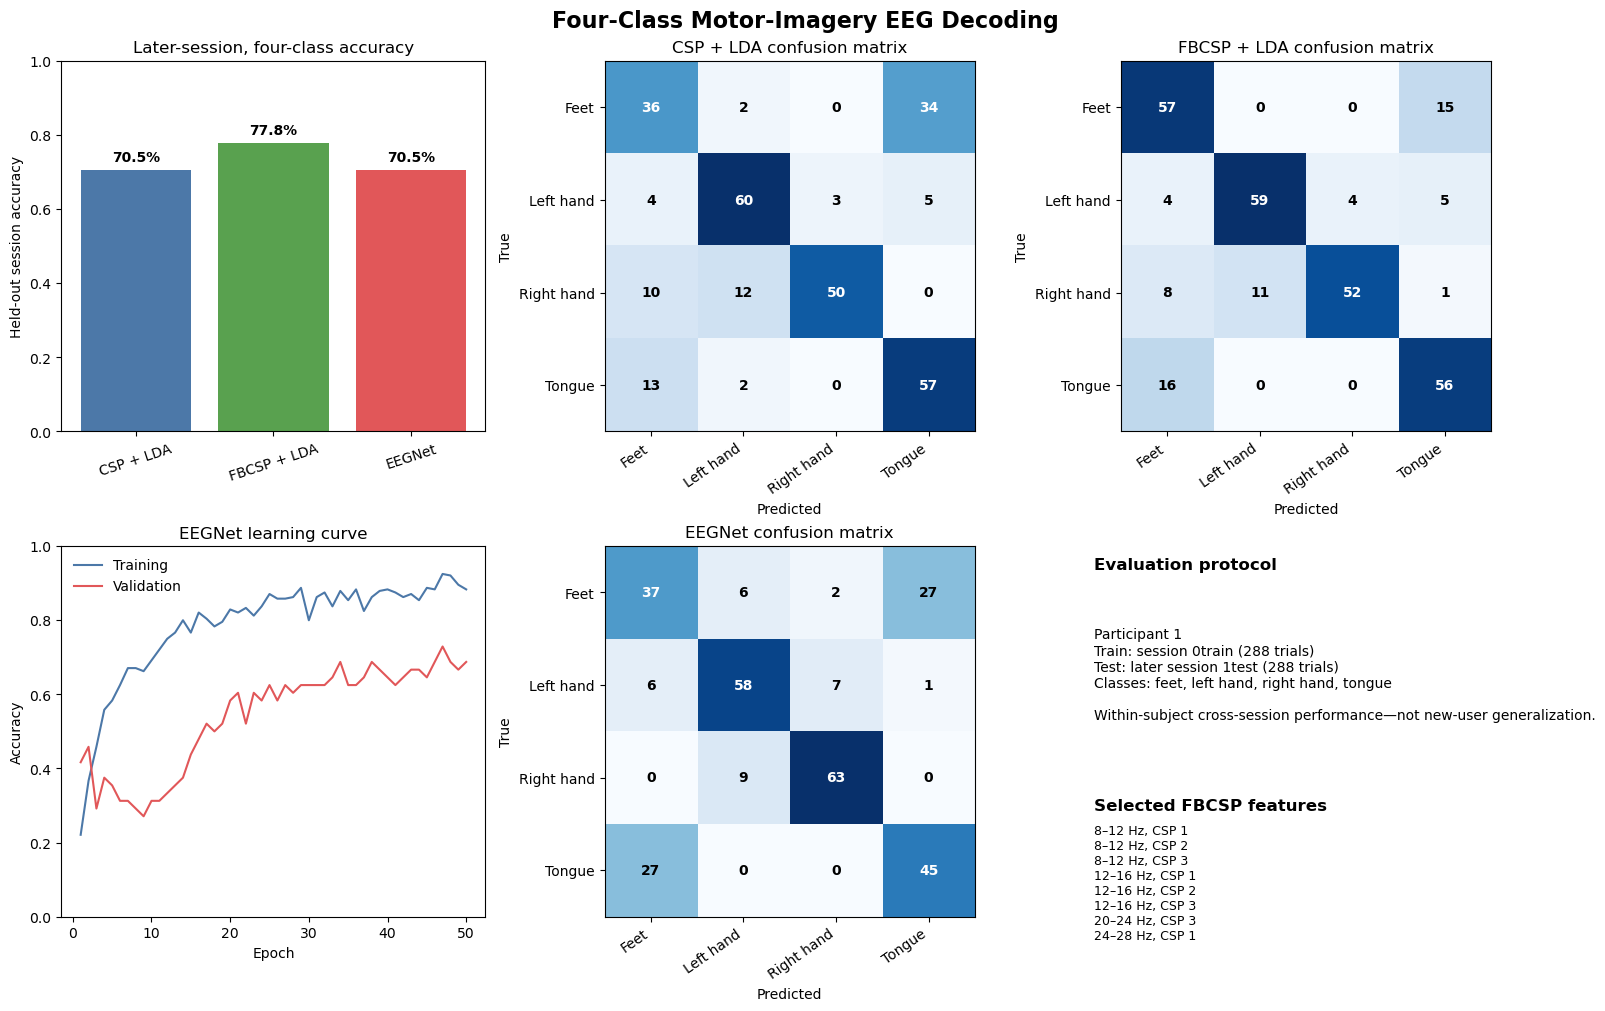

In [51]:
import matplotlib.pyplot as plt

method_names = ["CSP + LDA", "FBCSP + LDA", "EEGNet"]
held_out_accuracies = [accuracy, fbcsp_accuracy, test_accuracy]
confusions = [cm, fbcsp_confusion, test_confusion]

fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
fig.suptitle("Four-Class Motor-Imagery EEG Decoding", fontsize=16, fontweight="bold")

bar_colors = ["#4C78A8", "#59A14F", "#E15759"]
axes[0, 0].bar(method_names, held_out_accuracies, color=bar_colors)
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_ylabel("Held-out session accuracy")
axes[0, 0].set_title("Later-session, four-class accuracy")
axes[0, 0].tick_params(axis="x", rotation=18)
for i, value in enumerate(held_out_accuracies):
    axes[0, 0].text(i, value + 0.025, f"{value:.1%}", ha="center", fontweight="bold")

def draw_confusion(ax, matrix, title):
    ax.imshow(matrix, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks(range(4), CLASS_DISPLAY, rotation=35, ha="right")
    ax.set_yticks(range(4), CLASS_DISPLAY)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    threshold = matrix.max() / 2 if matrix.max() else 0
    for row in range(4):
        for col in range(4):
            color = "white" if matrix[row, col] > threshold else "black"
            ax.text(col, row, str(matrix[row, col]), ha="center", va="center", color=color, fontweight="bold")

draw_confusion(axes[0, 1], confusions[0], "CSP + LDA confusion matrix")
draw_confusion(axes[0, 2], confusions[1], "FBCSP + LDA confusion matrix")

axes[1, 0].plot(history["epoch"], history["train_accuracy"], label="Training", color="#4C78A8")
axes[1, 0].plot(history["epoch"], history["valid_accuracy"], label="Validation", color="#E15759")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].set_title("EEGNet learning curve")
axes[1, 0].legend(frameon=False)

draw_confusion(axes[1, 1], confusions[2], "EEGNet confusion matrix")

selected_labels = []
for feature_index in selector.get_support(indices=True):
    band_index, component_index = divmod(feature_index, 4)
    low, high = frequency_bands[band_index]
    selected_labels.append(f"{low}–{high} Hz, CSP {component_index + 1}")

axes[1, 2].axis("off")
axes[1, 2].text(0, 0.97, "Evaluation protocol", fontsize=12, fontweight="bold", va="top")
axes[1, 2].text(0, 0.78, "Participant 1\nTrain: session 0train (288 trials)\nTest: later session 1test (288 trials)\nClasses: feet, left hand, right hand, tongue\n\nWithin-subject cross-session performance—not new-user generalization.", va="top", fontsize=10)
axes[1, 2].text(0, 0.32, "Selected FBCSP features", fontsize=12, fontweight="bold", va="top")
axes[1, 2].text(0, 0.25, "\n".join(selected_labels), va="top", fontsize=9)

fig.savefig("motor_imagery_four_class_results.png", dpi=220, bbox_inches="tight")
plt.show()
